# Análisis velocimetría video Ngwerere con pyorc (versión corregida)

Flujo completo de trabajo:

1. Lectura de video
2. Puntos de control (GCPs)
3. Reproyección
4. Cálculo de velocidades (PIV) + **enmascarado de velocidades espurias**
5. Cálculo de caudal sobre el transecto

Basado en los notebooks de ejemplo de pyOpenRiverCam (02, 03 y 04).

---
# Parte 1 — Lectura de video

Primero hay que abrir el video y extraer fotogramas. `pyorc.Video` permite controlar qué fotogramas analizar (`start_frame`, `end_frame`) y aplicar correcciones.

Scanning video: 100%|██████████| 2/2 [00:00<00:00, 26.06it/s]


Dimensiones del fotograma: (1080, 1920, 3)


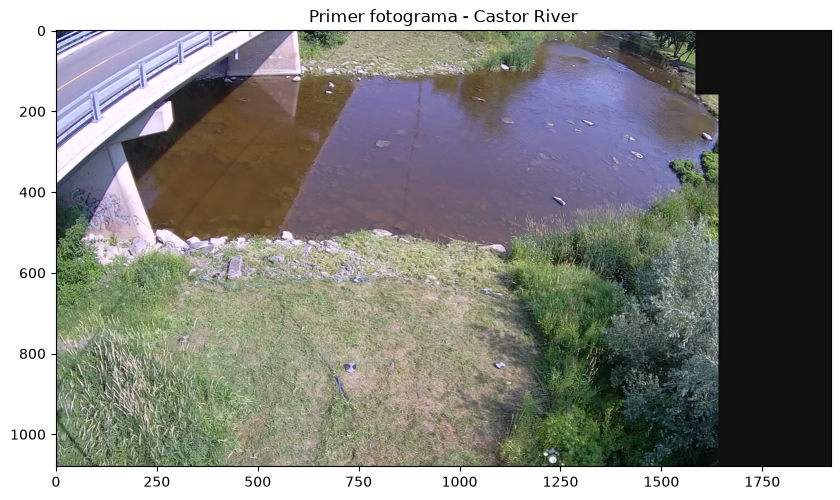

In [2]:
import pyorc
import matplotlib.pyplot as plt

video_file = "CastorRiver\\20190709\\Video4\\Video\\Castor_Canada_20190709_161305.mp4"

# por ahora solo leo 1 frame para ver cómo se ve
video = pyorc.Video(video_file, start_frame=0, end_frame=1)

frame = video.get_frame(0, method="rgb")

print(f"Dimensiones del fotograma: {frame.shape}")

plt.figure(figsize=(10, 6))
plt.imshow(frame)
plt.title("Primer fotograma - Castor River")
plt.show()

---
# Parte 2 — GCPs

Los GCPs son puntos de control que relacionan píxeles de la imagen con coordenadas reales (GPS/RTK). Sin esto no se puede georreferenciar nada.

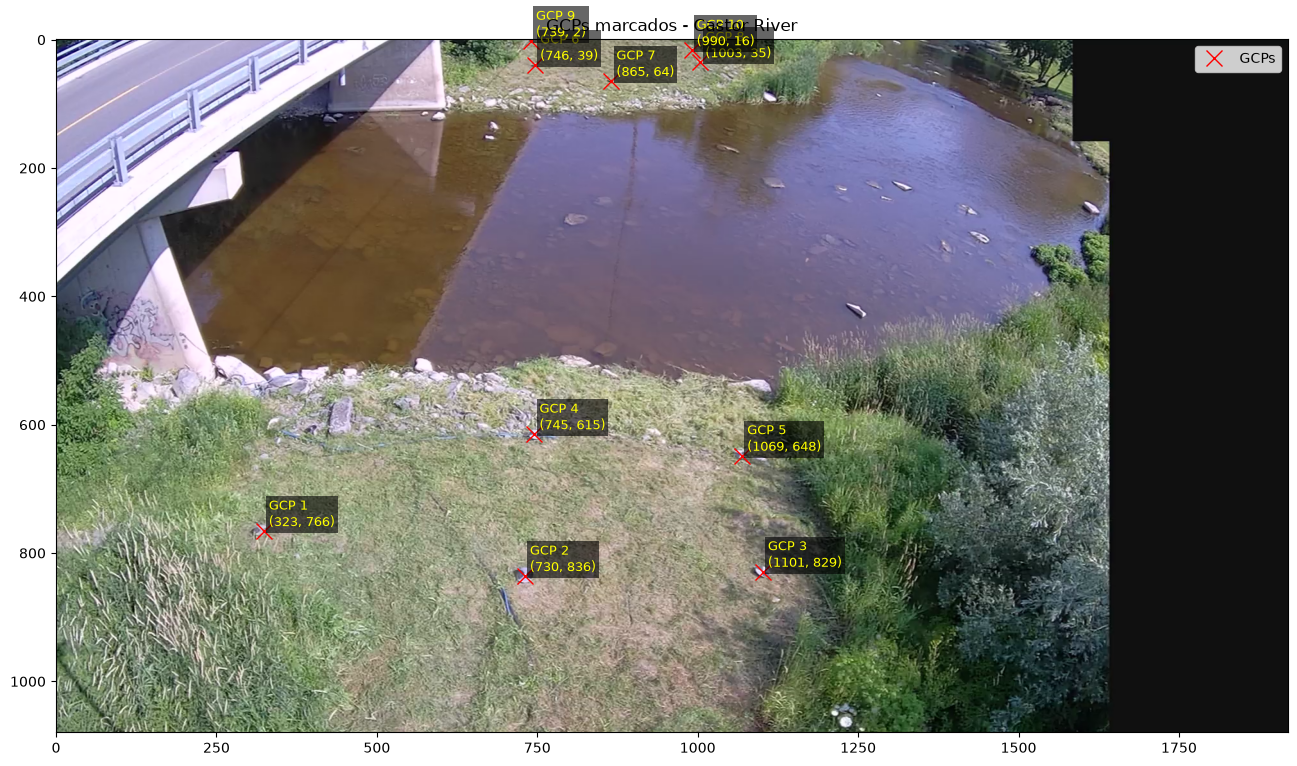

In [3]:
# coordenadas en píxeles (src) y coordenadas reales UTM (dst)

import pandas as pd
import matplotlib.pyplot as plt

gcp_data = pd.read_csv("CastorRiver\\20190709\\Video4\\GCPuse.csv")
gcp_data = gcp_data.rename(columns={
    "x.1": "x_pixel",
    "y.1": "y_pixel",
    "x": "x_utm",
    "y": "y_utm",
    "z": "z_utm"
})

gcps = dict(
    src=gcp_data[["x_pixel", "y_pixel"]].values.tolist(),
    dst=gcp_data[["x_utm", "y_utm", "z_utm"]].values.tolist(),
    z_0=3.128,     # nivel del agua
    h_ref=3.128,   # lectura de la mira
)

plt.figure(figsize=(16, 9))
plt.imshow(frame)

# Dibujar los GCPs
x, y = zip(*gcps["src"])
plt.plot(x, y, "rx", markersize=12, label="GCPs")

# Añadir número y coordenadas de cada GCP
for i, (xp, yp) in enumerate(gcps["src"], start=1):
    plt.text(
        xp + 8,                     # desplazamiento en x
        yp - 8,                     # desplazamiento en y
        f"GCP {i}\n({int(xp)}, {int(yp)})",
        color="yellow",
        fontsize=9,
        bbox=dict(facecolor="black", alpha=0.6, edgecolor="none", pad=2)
    )

plt.legend()
plt.title("GCPs marcados - Castor River")
plt.show()

---
# Parte 3 — Reproyección

`CameraConfig` usa los GCPs para calcular la transformación entre píxeles y metros reales. Esto permite reproyectar el video de perspectiva a vista ortorectificada (desde arriba).

También se define el área de interés (AOI) con las 4 esquinas y la resolución.

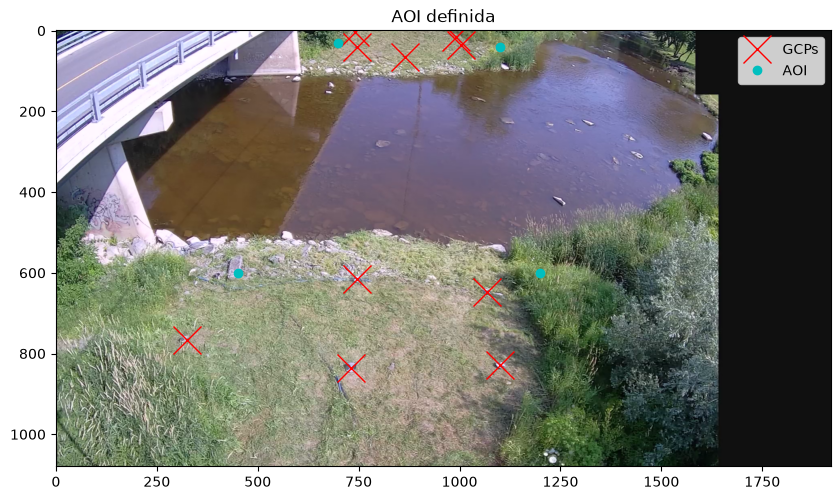

In [4]:
cam_config = pyorc.CameraConfig(
    height=frame.shape[0],
    width=frame.shape[1],
    gcps=gcps,
    crs=None,  # UTM zona 35S para Zambia
)

# esquinas del área de interés en píxeles
corners = [
    [450, 600],
    [700, 30],
    [1200, 600],
    [1100, 40],
]

cam_config.set_bbox_from_corners(corners)
cam_config.resolution = 0.01  # 1 cm por píxel
cam_config.window_size = 25   # para PIV después

plt.figure(figsize=(10, 6))
plt.imshow(frame)
plt.plot(*zip(*gcps["src"]), "rx", markersize=20, label="GCPs")
plt.plot(*zip(*corners), "co", label="AOI")
plt.legend()
plt.title("AOI definida")
plt.show()

In [5]:
# guardo para no tener que repetir esto cada vez
cam_config.to_file("CastorRiver\\20190709\\Video4\\castor_river_cam_config.json")
print("Config guardada")

Config guardada


Scanning video: 100%|██████████| 2/2 [00:00<00:00, 28.17it/s]


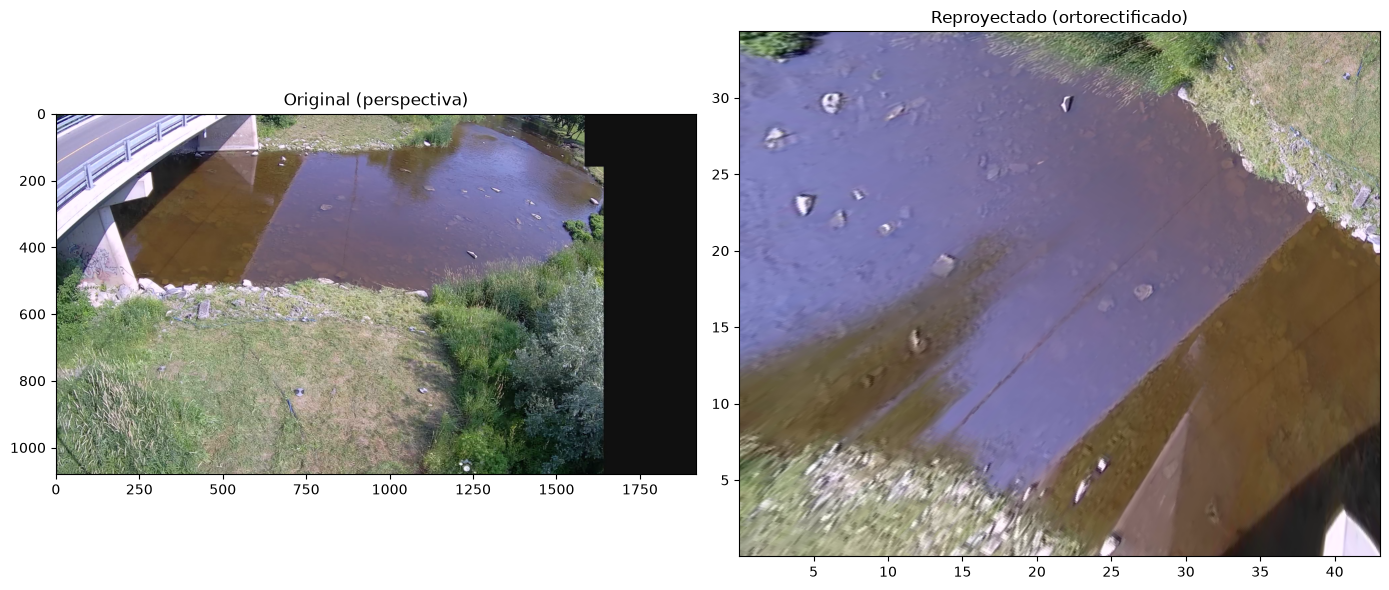

In [6]:
# prueba de reproyección
video_demo = pyorc.Video(
    video_file,
    camera_config=cam_config,
    start_frame=0,
    end_frame=1,
    h_a=0.0,
)

da_rgb_demo = video_demo.get_frames(method="rgb")
da_rgb_proj_demo = da_rgb_demo.frames.project()

# comparación antes/después
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(frame)
axes[0].set_title("Original (perspectiva)")

da_rgb_proj_demo[0].frames.plot(ax=axes[1])
axes[1].set_title("Reproyectado (ortorectificado)")

plt.tight_layout()
plt.show()

---
# Parte 4 — Velocidades (PIV)

Ahora sí proceso el video completo con LSPIV:
- Estabilización (usando zona de tierra firme)
- Normalización (resalta trazadores en movimiento)
- Reproyección de todos los frames
- PIV para calcular velocidades

In [8]:
from dask.diagnostics import ProgressBar

cam_config = pyorc.load_camera_config("CastorRiver\\20190709\\Video4\\castor_river_cam_config.json")

# zona de tierra firme para estabilizar
stabilize = [
    [500, 600],
    [1000, 600],
    [500, 1000],
    [1000, 1000],
]

video = pyorc.Video(
    video_file,
    camera_config=cam_config,
    start_frame=0,
    end_frame=125,  # ~5 segundos
    stabilize=stabilize,
    h_a=0.0,
)

da = video.get_frames()
da_norm = da.frames.normalize()
da_norm_proj = da_norm.frames.project(method="numpy")

print("Calculando velocidades...")
with ProgressBar():
    piv = da_norm_proj.frames.get_piv()

piv.to_netcdf("CastorRiver\\20190709\\Video4\\Video\\castor_river_piv.nc")
print("Listo, guardado en castor_river_piv.nc")

Scanning video: 100%|██████████| 126/126 [00:00<00:00, 160.87it/s]
Deriving stabilization parameters from second frame onwards: 100%|██████████| 125/125 [00:01<00:00, 77.94it/s]


Calculando velocidades...


Computing PIV per chunk:   0%|          | 0/10 [00:00<?, ?it/s]

[########################################] | 100% Completed | 5.88 sms


Computing PIV per chunk:  10%|█         | 1/10 [00:40<06:03, 40.41s/it]

...

[########################################] | 100% Completed | 4.66 sms


Computing PIV per chunk:  90%|█████████ | 9/10 [06:13<00:39, 39.71s/it]

[########################################] | 100% Completed | 5.28 sms


Computing PIV per chunk: 100%|██████████| 10/10 [06:40<00:00, 40.05s/it]


Listo, guardado en castor_river_piv.nc


Scanning video: 100%|██████████| 301/301 [00:01<00:00, 188.07it/s]


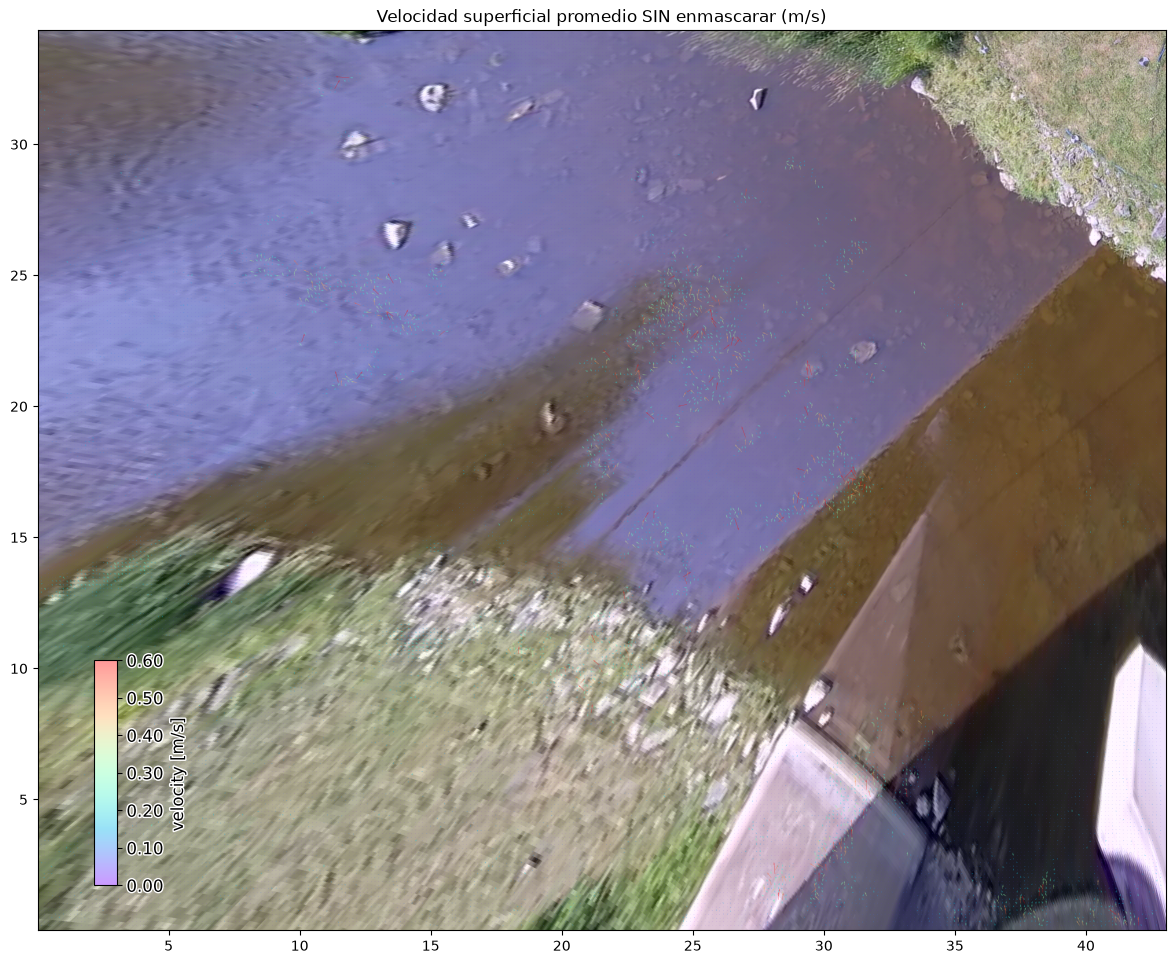

In [10]:
import xarray as xr
from matplotlib.colors import Normalize

ds = xr.open_dataset("CastorRiver\\20190709\\Video4\\Video\\castor_river_piv.nc")

video = pyorc.Video(video_file, start_frame=0, end_frame=300)
video.camera_config = ds.velocimetry.camera_config

da_rgb = video.get_frames(method="rgb")
da_rgb_proj = da_rgb.frames.project()

ds_mean = ds.mean(dim="time", keep_attrs=True)

p = da_rgb_proj[0].frames.plot()
ds_mean.velocimetry.plot(
    ax=p.axes,
    alpha=0.4,
    norm=Normalize(vmax=0.6, clip=False),
    add_colorbar=True,
)

plt.title("Velocidad superficial promedio SIN enmascarar (m/s)")
plt.show()

---

El PIV crudo contiene vectores espurios
(incluso sobre tierra firme) que distorsionan el caudal — por eso el percentil 5 salía negativo.

Se aplican las máscaras en el mismo orden que el notebook 03 original:
1. Máscaras por valor individual (`corr`, `minmax`)
2. Máscaras temporales (`rolling`, `outliers`, `variance`)
3. Máscara de ángulo con tolerancia relajada (`0.5*pi`), adecuada para este arroyo
   somero con rocas y obstrucciones
4. Máscaras finales (`count`, `window_mean` espacial con tiempo reducido)

In [ ]:
import copy
import numpy as np

ds_mask = copy.deepcopy(ds)
ds_mask.velocimetry.mask.corr(inplace=True)
ds_mask.velocimetry.mask.minmax(inplace=True)
ds_mask.velocimetry.mask.rolling(inplace=True)
ds_mask.velocimetry.mask.outliers(inplace=True)
ds_mask.velocimetry.mask.variance(inplace=True)
ds_mask.velocimetry.mask.angle(angle_tolerance=0.5 * np.pi)
ds_mask.velocimetry.mask.count(inplace=True)
ds_mask.velocimetry.mask.window_mean(wdw=2, inplace=True, tolerance=0.5, reduce_time=True)

# guardar resultados enmascarados (con encoding para archivo pequeño)
ds_mask.velocimetry.set_encoding()
ds_mask.to_netcdf("CastorRiver\\20190709\\Video4\\Video\\castor_river_piv_masked.nc")
print("Resultados enmascarados guardados en castor_river_piv_masked.nc")

Resultados enmascarados guardados en castor_river_piv_masked.nc


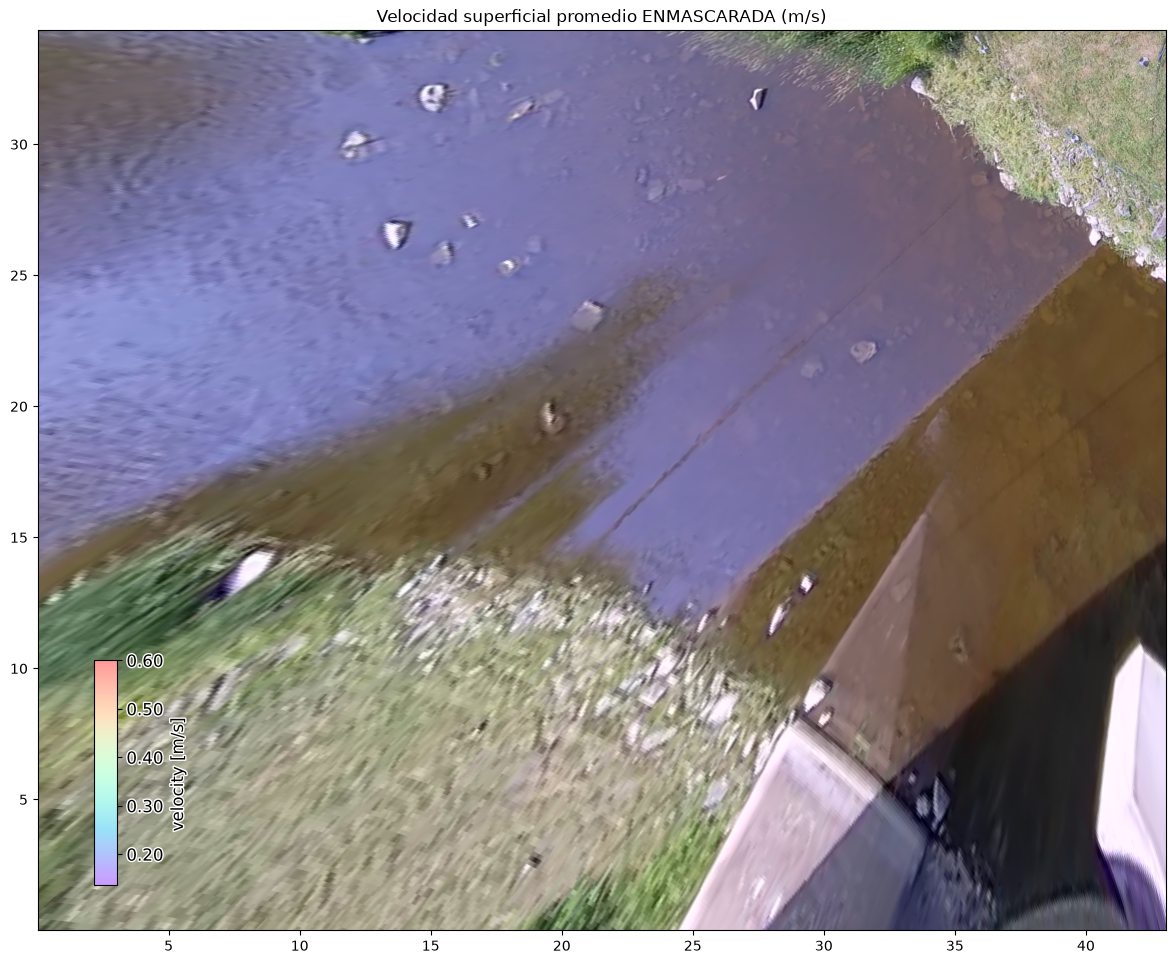

In [14]:
# comparar el campo de velocidades enmascarado
ds_mean_mask = ds_mask.mean(dim="time", keep_attrs=True)

p = da_rgb_proj[0].frames.plot()
ds_mean_mask.velocimetry.plot(
    ax=p.axes,
    alpha=0.4,
    norm=Normalize(vmax=0.6, clip=False),
    add_colorbar=True,
)
plt.title("Velocidad superficial promedio ENMASCARADA (m/s)")
plt.show()

---
# Parte 5 — Caudal

Para calcular el caudal necesito:
1. Batimetría del transecto (archivo csv con x, y, z)
2. Extraer velocidades en esos puntos **desde el dataset enmascarado**
3. Rellenar huecos con perfil logarítmico (`log_interp`) y convertir velocidad
   superficial a velocidad media (factor 0.9, valor por defecto)
4. Integrar a lo largo del transecto

**Correcciones aplicadas respecto a la versión anterior:**
- Se usa `ngwerere_masked.nc` en lugar del PIV crudo
- `get_transect(..., crs=32735, rolling=4)` como en el notebook 04
- `fill_method="log_interp"` en lugar de `"zeros"`

In [ ]:
import pandas as pd

# reabrir los resultados enmascarados
ds = xr.open_dataset("ngwerere/ngwerere_masked.nc")

cross_section = pd.read_csv("ngwerere/ngwerere_cross_section.csv")
print(f"Puntos: {len(cross_section)}")
cross_section.head()

In [ ]:
# CORREGIDO: crs=32735 (batimetría en UTM 35S) y rolling=4 (suavizado temporal)
transect = ds.velocimetry.get_transect(
    cross_section["x"].values,
    cross_section["y"].values,
    cross_section["z"].values,
    crs=32735,
    rolling=4,
)
print(transect)

In [ ]:
# CORREGIDO: fill_method="log_interp" (perfil logarítmico) en lugar de "zeros"
# v_corr=0.9 es el valor por defecto (velocidad media = 0.9 x velocidad superficial)
q_transect = transect.transect.get_q(fill_method="log_interp")
q_transect

In [ ]:
# integrar para obtener caudal total
q_transect.transect.get_river_flow()
caudal = q_transect["river_flow"]

print("\n" + "=" * 50)
print("RESULTADOS")
print("=" * 50)
print("\nCaudal por percentil (m³/s):")
print(caudal.to_dataframe().to_string())

q_med = float(caudal.sel(quantile=0.5).values)
q_05 = float(caudal.sel(quantile=0.05).values)
q_95 = float(caudal.sel(quantile=0.95).values)

print(f"\n{'─' * 50}")
print(f"Caudal (mediana):  {q_med:.4f} m³/s")
print("Incertidumbre:")
print(f"  P5:  {q_05:.4f} m³/s")
print(f"  P95: {q_95:.4f} m³/s")
print(f"{'─' * 50}\n")

## Visualización del transecto (CORREGIDA)

Correcciones:
- Se eliminó el kwarg inválido `add_legend` que causaba el `AttributeError`
  (los kwargs de `transect.plot()` se pasan a `matplotlib.quiver`)
- El perfil se grafica con `v_eff` directamente (velocidad efectiva por punto)
- El transecto sobre el campo de velocidades se dibuja con el método nativo
  `transect.plot(mode="local")`, que convierte correctamente UTM → coordenadas locales
  (antes se dibujaban coordenadas UTM sobre ejes locales y la línea quedaba fuera del gráfico)

In [ ]:
# perfil de velocidad efectiva y distribución de caudal a lo largo del transecto
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# velocidad efectiva (mediana = quantile index 2)
q_transect["v_eff"].isel(quantile=2).plot(ax=axes[0])
axes[0].set_title("Velocidad efectiva a lo largo del transecto (mediana)")
axes[0].set_xlabel("Punto del transecto")
axes[0].set_ylabel("Velocidad (m/s)")
axes[0].grid(True, alpha=0.3)

# distribución del caudal integrado en profundidad
q_median = q_transect.sel(quantile=0.5)
axes[1].fill_between(
    q_median["scoords"].values,
    q_median["q"].values,
    alpha=0.5,
    color="steelblue",
    label="q por segmento",
)
axes[1].plot(q_median["scoords"].values, q_median["q"].values, "b-", linewidth=2)
axes[1].set_xlabel("Distancia a lo largo del transecto (m)")
axes[1].set_ylabel("Velocidad integrada en profundidad (m²/s)")
axes[1].set_title("Distribución de caudal en el transecto")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# ubicación del transecto sobre el campo de velocidades (proyección local nativa)
norm = Normalize(vmin=0.0, vmax=0.6, clip=False)
ds_mean = ds.mean(dim="time", keep_attrs=True)

p = da_rgb_proj[0].frames.plot(mode="local")

# campo de velocidades enmascarado
ds_mean.velocimetry.plot(
    ax=p.axes,
    mode="local",
    alpha=0.4,
    norm=norm,
)

# CORREGIDO: el método nativo maneja la transformación UTM -> local
q_transect.isel(quantile=2).transect.plot(
    ax=p.axes,
    mode="local",
    cmap="rainbow",
    norm=norm,
    width=2,
    add_colorbar=True,
)

p.axes.set_title(f"Ubicación del transecto — Q mediana = {q_med:.3f} m³/s")
plt.tight_layout()
plt.show()

In [ ]:
# vista de realidad aumentada: transecto sobre la perspectiva original de la cámara
p = da_rgb[0].frames.plot(mode="camera")

ds_mean.velocimetry.plot(
    ax=p.axes,
    mode="camera",
    alpha=0.3,
    norm=norm,
)

q_transect.isel(quantile=2).transect.plot(
    ax=p.axes,
    mode="camera",
    cmap="rainbow",
    norm=norm,
    width=2,
    add_colorbar=True,
)

p.axes.set_title("Vista de cámara (realidad aumentada)")
plt.show()

print(f"\nAnálisis completo. Caudal mediana: {q_med:.4f} m³/s (P5: {q_05:.4f} | P95: {q_95:.4f})")

In [ ]:
import matplotlib
print(matplotlib.__version__)

